# Introduction to Deepfake Detection
Deepfakes are synthetic media (usually videos or images) created using deep learning techniques. They convincingly replace a person’s likeness in existing media with someone else’s, often leading to misinformation and potential harm. Detecting deepfakes is crucial for maintaining trust in visual content.

**on this project we will use dataset** ***140k Real and Fake Faces***

This dataset consists of all 70k REAL faces from the Flickr dataset collected by Nvidia, as well as 70k fake faces sampled from the 1 Million FAKE faces (generated by StyleGAN) that was provided by Bojan.

In this dataset, I convenient combined both dataset, resized all the images into 256px, and split the data into train, validation and test set. I also included some CSV files for convenience.

In [13]:
import os
import tensorflow as tf
import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.applications import Xception
from sklearn.metrics import classification_report
from tensorflow.keras import Model


In [1]:
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Currently, memory growth needs to be the same across GPUs
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth Enabled")
    except RuntimeError as e:
        print(e)

GPU Memory Growth Enabled


In [3]:
data_folder = "E:\Deepfake detection"
train_data = pd.read_csv("train.csv")
test_data  = pd.read_csv("test.csv")
validation_data = pd.read_csv("valid.csv")

In [4]:
path="E:/Deepfake detection/real_vs_fake/real-vs-fake"

# Preprocessing and Augmentation
The ImageDataGenerator is a powerful tool for data augmentation and preprocessing in deep learning. It generates batches of augmented image data on-the-fly during training.

In [5]:
train_image_generator = ImageDataGenerator(rescale=1./255.,preprocessing_function=preprocess_input)

train_data_generator = train_image_generator.flow_from_dataframe(
    dataframe=train_data,
    directory=path,
    x_col ='path',
    y_col ='label_str',
    color_mode="rgb",
    target_size=(256, 256),
    class_mode="binary",
    batch_size=32,
    shuffle = True
)


Found 100000 validated image filenames belonging to 2 classes.


In [6]:
validation_image_generator = ImageDataGenerator(rescale=1./255.,preprocessing_function=preprocess_input)
test_image_generator = ImageDataGenerator(rescale=1./255.,preprocessing_function=preprocess_input)

validation_data_generator = validation_image_generator.flow_from_dataframe(
    dataframe=validation_data,
    directory=path,
    x_col ='path',
    y_col ='label_str',
    color_mode="rgb",
    target_size=(256, 256),
    class_mode="binary",
    batch_size=32,
    shuffle = True
)


test_data_generator = test_image_generator.flow_from_dataframe(
    dataframe=test_data,
    directory=path,
    x_col ='path',
    y_col ='label_str',
    color_mode="rgb",
    target_size=(256, 256),
    class_mode="binary",
    batch_size=32,
    shuffle = False
)


Found 20000 validated image filenames belonging to 2 classes.
Found 20000 validated image filenames belonging to 2 classes.


# visualization

In [7]:
labels = train_data_generator.class_indices
class_names = list(labels.keys())
print('class names:',class_names)

class names: ['fake', 'real']


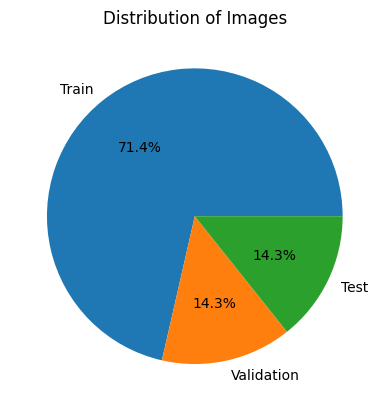

In [8]:
import matplotlib.pyplot as plt

labels = ["Train", "Validation", "Test"]
counts = [len(train_data), len(validation_data), len(test_data)]

fig, ax = plt.subplots()
ax.pie(counts, labels=labels, autopct="%1.1f%%")
ax.set_title("Distribution of Images")
plt.show()


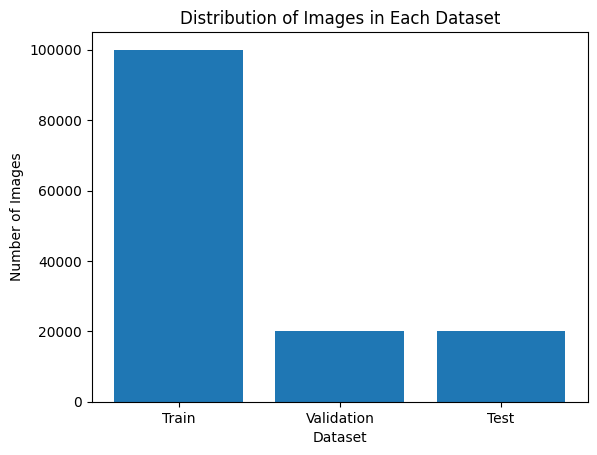

In [9]:
import matplotlib.pyplot as plt

train_size = len(train_data)
validation_size = len(validation_data)
test_size = len(test_data)

fig, ax = plt.subplots()
x = ['Train', 'Validation', 'Test']
y = [train_size, validation_size, test_size]
ax.bar(x, y)
ax.set_xlabel('Dataset')
ax.set_ylabel('Number of Images')
ax.set_title('Distribution of Images in Each Dataset')

plt.show()

# Convolutional Neural Networks (CNNs)
CNNs have been widely used for image classification tasks. They excel at learning hierarchical features from raw pixel data. In the context of deepfake detection, CNNs can analyze patterns and features in images to distinguish between real and manipulated content.

In [10]:
model_cnn = Sequential()

model_cnn.add(Conv2D(32,kernel_size=(3, 3), activation='relu', input_shape=(256, 256, 3)))
model_cnn.add(MaxPooling2D((2, 2)))
model_cnn.add(Conv2D(64, (3, 3), activation='relu'))
model_cnn.add(MaxPooling2D((2, 2)))
model_cnn.add(Conv2D(64, (3, 3), activation='relu'))
model_cnn.add(MaxPooling2D((2, 2)))
model_cnn.add(Dropout(0.2))
model_cnn.add(Flatten())
model_cnn.add(Dense(64, activation='relu'))
model_cnn.add(Dropout(0.2))
model_cnn.add(Dense(1, activation='sigmoid'))

In [11]:
model_cnn.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 254, 254, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 127, 127, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 62, 62, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 60, 60, 64)        36928     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 30, 30, 64)       0

In [12]:
model_cnn.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [13]:
history = model_cnn.fit(train_data_generator ,epochs = 10,validation_data= (validation_data_generator))

Epoch 1/10
3125/3125 [==============================] - 1093s 349ms/step - loss: 0.3738 - accuracy: 0.8298 - val_loss: 0.2143 - val_accuracy: 0.9137
Epoch 2/10
3125/3125 [==============================] - 255s 82ms/step - loss: 0.1772 - accuracy: 0.9303 - val_loss: 0.1420 - val_accuracy: 0.9470
Epoch 3/10
3125/3125 [==============================] - 231s 74ms/step - loss: 0.1180 - accuracy: 0.9550 - val_loss: 0.1132 - val_accuracy: 0.9565
Epoch 4/10
3125/3125 [==============================] - 231s 74ms/step - loss: 0.0920 - accuracy: 0.9655 - val_loss: 0.0958 - val_accuracy: 0.9646
Epoch 5/10
3125/3125 [==============================] - 230s 74ms/step - loss: 0.0759 - accuracy: 0.9715 - val_loss: 0.0991 - val_accuracy: 0.9658
Epoch 6/10
3125/3125 [==============================] - 231s 74ms/step - loss: 0.0638 - accuracy: 0.9766 - val_loss: 0.0883 - val_accuracy: 0.9674
Epoch 7/10
3125/3125 [==============================] - 230s 74ms/step - loss: 0.0555 - accuracy: 0.9795 - val_loss:

In [14]:
test_loss, test_accuracy = model_cnn.evaluate(test_data_generator)
print(f'Loss: {test_loss}, Accuracy: {test_accuracy}')

625/625 [==============================] - 188s 301ms/step - loss: 0.0725 - accuracy: 0.9756
Loss: 0.07250198721885681, Accuracy: 0.975600004196167


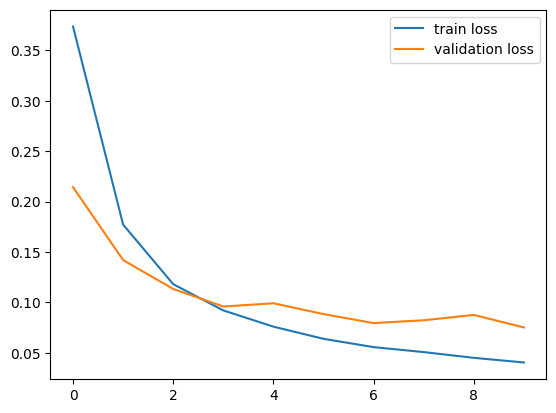

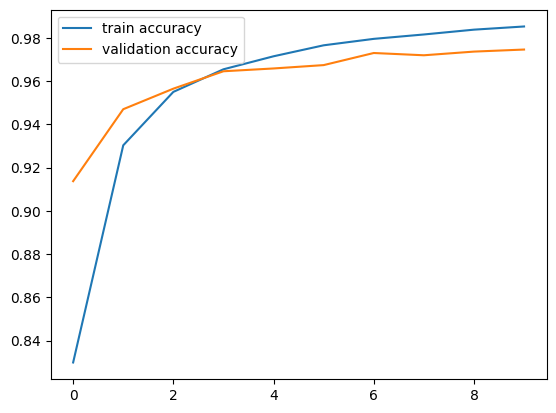

In [15]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.legend()
plt.show()


plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()


625/625 [==============================] - 34s 55ms/step


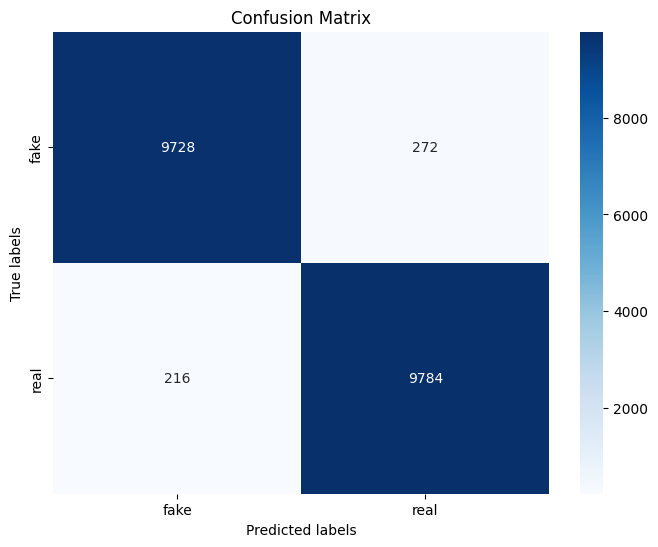

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

predictions = model_cnn.predict(test_data_generator)
predicted_labels = np.where(predictions > 0.5, 1, 0)
true_labels = test_data_generator.classes

conf_matrix = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data_generator.class_indices,
            yticklabels=test_data_generator.class_indices)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()


In [17]:
class_names = list(test_data_generator.class_indices.keys())
report = classification_report(true_labels, predicted_labels, target_names=class_names)
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

        fake       0.98      0.97      0.98     10000
        real       0.97      0.98      0.98     10000

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000



# XceptionNet
XceptionNet is a deep learning architecture based on CNNs. It was designed to improve the efficiency of feature extraction by replacing standard convolutional layers with depthwise separable convolutions. XceptionNet has been successfully applied to various computer vision tasks, including deepfake detection.

In [18]:
base_model = Xception(weights='imagenet',include_top=False,input_shape=(256, 256, 3))


In [19]:
for layer in base_model.layers:
    layer.trainable = False

Xception_model = Sequential()
Xception_model.add(base_model)
Xception_model.add(Flatten())
Xception_model.add(BatchNormalization())
Xception_model.add(Dense(256, activation='relu'))
Xception_model.add(Dropout(0.5))
Xception_model.add(Dense(128, activation='relu'))
Xception_model.add(Dropout(0.5))
Xception_model.add(BatchNormalization())
Xception_model.add(Dense(1, activation='sigmoid'))

Xception_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 xception (Functional)       (None, 8, 8, 2048)        20861480  
                                                                 
 flatten_1 (Flatten)         (None, 131072)            0         
                                                                 
 batch_normalization_4 (Batc  (None, 131072)           524288    
 hNormalization)                                                 
                                                                 
 dense_2 (Dense)             (None, 256)               33554688  
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_3 (Dense)             (None, 128)               32896     
                                                      

In [20]:
Xception_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [21]:
history = Xception_model.fit(train_data_generator ,epochs = 10,validation_data= (validation_data_generator))
print(history.history)

Epoch 1/10
3125/3125 [==============================] - 366s 116ms/step - loss: 0.4600 - accuracy: 0.7838 - val_loss: 0.3680 - val_accuracy: 0.8325
Epoch 2/10
3125/3125 [==============================] - 364s 117ms/step - loss: 0.3467 - accuracy: 0.8496 - val_loss: 0.3057 - val_accuracy: 0.8689
Epoch 3/10
3125/3125 [==============================] - 364s 117ms/step - loss: 0.2953 - accuracy: 0.8750 - val_loss: 0.2770 - val_accuracy: 0.8836
Epoch 4/10
3125/3125 [==============================] - 365s 117ms/step - loss: 0.2511 - accuracy: 0.8962 - val_loss: 0.2545 - val_accuracy: 0.8932
Epoch 5/10
3125/3125 [==============================] - 364s 117ms/step - loss: 0.2137 - accuracy: 0.9135 - val_loss: 0.2391 - val_accuracy: 0.9009
Epoch 6/10
3125/3125 [==============================] - 365s 117ms/step - loss: 0.1881 - accuracy: 0.9247 - val_loss: 0.2347 - val_accuracy: 0.9050
Epoch 7/10
3125/3125 [==============================] - 364s 117ms/step - loss: 0.1638 - accuracy: 0.9354 - val_

In [22]:
test_loss, test_accuracy = Xception_model.evaluate(test_data_generator)
print(f'Loss: {test_loss}, Accuracy: {test_accuracy}')

625/625 [==============================] - 59s 94ms/step - loss: 0.2290 - accuracy: 0.9136
Loss: 0.22903139889240265, Accuracy: 0.9136000275611877


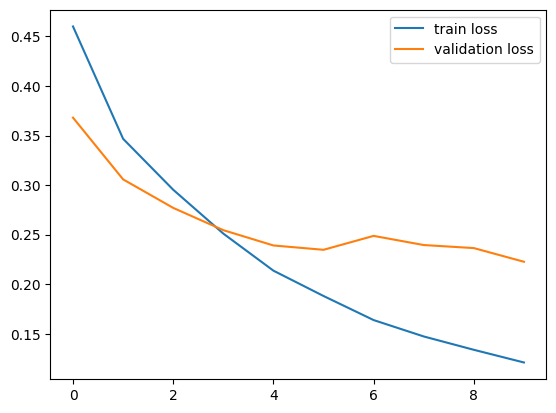

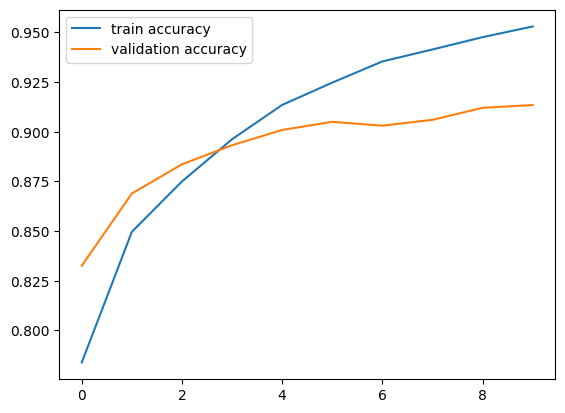

In [23]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()

625/625 [==============================] - 57s 91ms/step


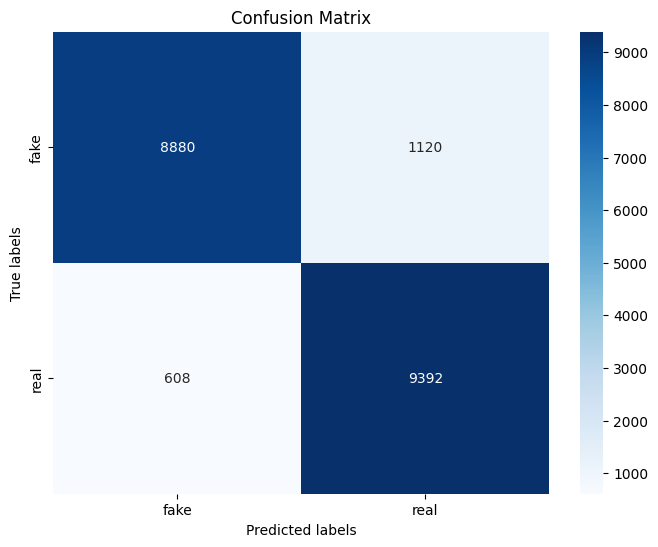

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

predictions = Xception_model.predict(test_data_generator)
predicted_labels = np.where(predictions > 0.5, 1, 0)
true_labels = test_data_generator.classes
conf_matrix = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data_generator.class_indices,
            yticklabels=test_data_generator.class_indices)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()


In [25]:
class_names = list(test_data_generator.class_indices.keys())
report = classification_report(true_labels, predicted_labels, target_names=class_names)

print("Classification Report:")
print(report)


Classification Report:
              precision    recall  f1-score   support

        fake       0.94      0.89      0.91     10000
        real       0.89      0.94      0.92     10000

    accuracy                           0.91     20000
   macro avg       0.91      0.91      0.91     20000
weighted avg       0.91      0.91      0.91     20000



In [26]:
# This should show 54 million parameters
Xception_model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 xception (Functional)       (None, 8, 8, 2048)        20861480  
                                                                 
 flatten_1 (Flatten)         (None, 131072)            0         
                                                                 
 batch_normalization_4 (Batc  (None, 131072)           524288    
 hNormalization)                                                 
                                                                 
 dense_2 (Dense)             (None, 256)               33554688  
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_3 (Dense)             (None, 128)               32896     
                                                      

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.xception import preprocess_input  # Change to vgg16 if you are using VGG16 instead
import tensorflow as tf

# 1. Reset the Generators
# Train Generator WITH Data Augmentation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

# Validation Generator (NO Data Augmentation)
val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_dir = '1000_videos/train'
val_dir = '1000_videos/validation'

# 2. Flow Data from Directories
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(256, 256),
    batch_size=8,
    class_mode='binary',
    shuffle=True
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(256, 256),
    batch_size=8,
    class_mode='binary',
    shuffle=False
)


Found 11633 images belonging to 2 classes.
Found 2400 images belonging to 2 classes.


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import Xception
import tensorflow as tf

# 1. Rebuild the model (Replacing Flatten with GlobalAveragePooling2D)
base_model = Xception(weights='imagenet', include_top=False, input_shape=(256, 256, 3))
base_model.trainable = False 

Xception_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(), # <--- This is a GREAT choice for Xception!
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(1, activation='sigmoid')
])

# 2. Compile 
Xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), 
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. Start Training
history_finetune = Xception_model.fit(
    train_data_generator, 
    validation_data=validation_data_generator,
    epochs=10
)

Epoch 1/10
3125/3125 [==============================] - 347s 110ms/step - loss: 0.5870 - accuracy: 0.7066 - val_loss: 0.4463 - val_accuracy: 0.7879
Epoch 2/10
3125/3125 [==============================] - 343s 110ms/step - loss: 0.4837 - accuracy: 0.7692 - val_loss: 0.4055 - val_accuracy: 0.8148
Epoch 3/10
3125/3125 [==============================] - 343s 110ms/step - loss: 0.4437 - accuracy: 0.7931 - val_loss: 0.3852 - val_accuracy: 0.8285
Epoch 4/10
3125/3125 [==============================] - 343s 110ms/step - loss: 0.4167 - accuracy: 0.8100 - val_loss: 0.3697 - val_accuracy: 0.8339
Epoch 5/10
3125/3125 [==============================] - 343s 110ms/step - loss: 0.3984 - accuracy: 0.8199 - val_loss: 0.3553 - val_accuracy: 0.8446
Epoch 6/10
3125/3125 [==============================] - 343s 110ms/step - loss: 0.3813 - accuracy: 0.8284 - val_loss: 0.3497 - val_accuracy: 0.8472
Epoch 7/10
3125/3125 [==============================] - 344s 110ms/step - loss: 0.3653 - accuracy: 0.8392 - val_

In [ ]:
import tensorflow as tf

# 1. Unfreeze the base model
Xception_model.layers[0].trainable = True

# 2. Re-compile with an EVEN SMALLER learning rate 
Xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.000001), 
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# # 3. Train for 10 more epochs using YOUR existing variables
history_finetune_2 = Xception_model.fit(
    train_generator,                      
    validation_data=validation_generator, 
    epochs=10
)

Epoch 1/10
1455/1455 [==============================] - 270s 182ms/step - loss: 0.9862 - accuracy: 0.6023 - val_loss: 1.0520 - val_accuracy: 0.6242
Epoch 2/10
1455/1455 [==============================] - 172s 118ms/step - loss: 0.8051 - accuracy: 0.6641 - val_loss: 0.8608 - val_accuracy: 0.6654
Epoch 3/10
1455/1455 [==============================] - 173s 119ms/step - loss: 0.7032 - accuracy: 0.7041 - val_loss: 0.7394 - val_accuracy: 0.7021
Epoch 4/10
1455/1455 [==============================] - 169s 116ms/step - loss: 0.6329 - accuracy: 0.7368 - val_loss: 0.6381 - val_accuracy: 0.7383
Epoch 5/10
1455/1455 [==============================] - 170s 117ms/step - loss: 0.5735 - accuracy: 0.7587 - val_loss: 0.5774 - val_accuracy: 0.7592
Epoch 6/10
1455/1455 [==============================] - 171s 117ms/step - loss: 0.5434 - accuracy: 0.7723 - val_loss: 0.5342 - val_accuracy: 0.7729
Epoch 7/10
1455/1455 [==============================] - 170s 117ms/step - loss: 0.5048 - accuracy: 0.7843 - val_

In [ ]:
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Load your manually saved model
print("Loading saved model...")
loaded_model = load_model('another_deepfake_xception.h5')
print("Model loaded successfully!")

# 1. Setup Callbacks
checkpoint = ModelCheckpoint(
    'more_deepfake_xception.h5', 
    monitor='val_accuracy', 
    save_best_only=True, 
    mode='max', 
    verbose=1
)

# EarlyStopping: Stops training if the val_accuracy doesn't improve for 5 epochs in a row
early_stop = EarlyStopping(
    monitor='val_accuracy', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)

# 2. Continue Training!
print("Resuming training from where we left off...")

history_finetune_3 = loaded_model.fit(
    train_generator, 
    validation_data=validation_generator,
    epochs=80, 
    callbacks=[checkpoint, early_stop]
)

Loading saved model...
Model loaded successfully!
Resuming training from where we left off...
Epoch 1/80
1455/1455 [==============================] - ETA: 0s - loss: 0.2301 - accuracy: 0.9085
Epoch 1: val_accuracy improved from -inf to 0.88208, saving model to more_deepfake_xception.h5
1455/1455 [==============================] - 327s 222ms/step - loss: 0.2301 - accuracy: 0.9085 - val_loss: 0.2655 - val_accuracy: 0.8821
Epoch 2/80
1455/1455 [==============================] - ETA: 0s - loss: 0.2343 - accuracy: 0.9065
Epoch 2: val_accuracy did not improve from 0.88208
1455/1455 [==============================] - 166s 114ms/step - loss: 0.2343 - accuracy: 0.9065 - val_loss: 0.2624 - val_accuracy: 0.8813
Epoch 3/80
1455/1455 [==============================] - ETA: 0s - loss: 0.2367 - accuracy: 0.9042
Epoch 3: val_accuracy improved from 0.88208 to 0.88625, saving model to more_deepfake_xception.h5
1455/1455 [==============================] - 157s 108ms/step - loss: 0.2367 - accuracy: 0.9042

another_deepfake_xception
Epoch 30: val_accuracy did not improve from 0.88750
Restoring model weights from the end of the best epoch: 25.
1455/1455 [==============================] - 170s 117ms/step - loss: 0.2222 - accuracy: 0.9111 - val_loss: 0.2592 - val_accuracy: 0.8871
Epoch 30: early stopping

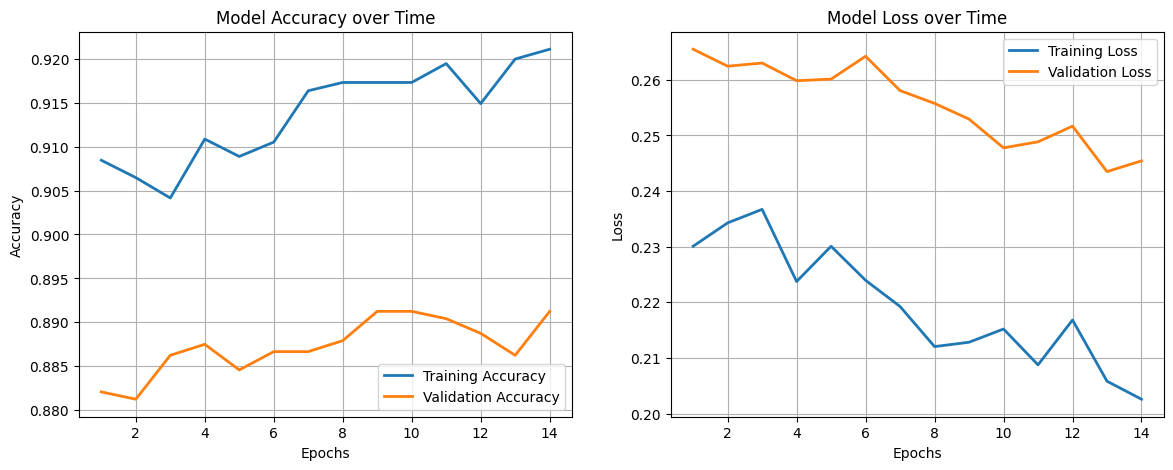

In [ ]:
import matplotlib.pyplot as plt

# Grab the history data from your training run
acc = history_finetune_3.history['accuracy']
val_acc = history_finetune_3.history['val_accuracy']
loss = history_finetune_3.history['loss']
val_loss = history_finetune_3.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy over Time')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', linewidth=2)
plt.title('Model Loss over Time')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.show()

In [3]:
from tensorflow.keras.models import load_model

# Load either the auto-saved best model OR your manually saved final model
my_model = load_model('more_deepfake_xception.h5')

print("Model loaded and ready to use!")

Model loaded and ready to use!


Running predictions... This might take a minute.
300/300 [==============================] - 6s 19ms/step

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

    Fake (0)       0.81      0.96      0.88      1200
    Real (1)       0.96      0.78      0.86      1200

    accuracy                           0.87      2400
   macro avg       0.88      0.87      0.87      2400
weighted avg       0.88      0.87      0.87      2400


--- CONFUSION MATRIX ---


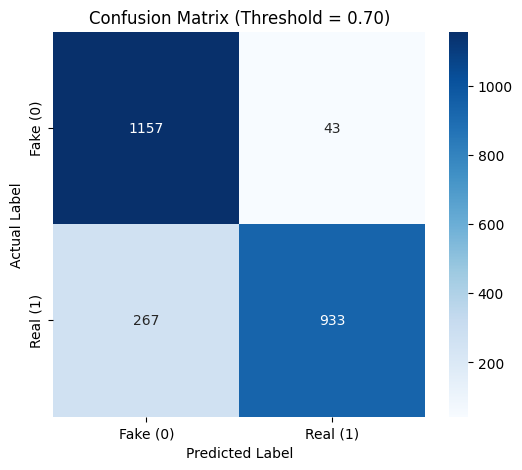

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Get the true labels directly from the generator
y_true = validation_generator.classes

# 2. Get the model's raw probability predictions
print("Running predictions... This might take a minute.")
loaded_model = load_model('more_deepfake_xception.h5')
predictions = loaded_model.predict(validation_generator)

# 3. Convert probabilities to 0s and 1s using the strict 0.70 threshold
y_pred = (predictions > 0.70).astype(int).flatten()

# 4. Print the Classification Report (Accuracy, Precision, Recall, F1-Score)
print("\n--- CLASSIFICATION REPORT ---")
target_names = ['Fake (0)', 'Real (1)'] 
print(classification_report(y_true, y_pred, target_names=target_names))

# 5. Plot a visual Confusion Matrix
print("\n--- CONFUSION MATRIX ---")
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix (Threshold = 0.70)')
plt.savefig('confusion_matrix_070.png', dpi=300, bbox_inches='tight') # Saves high-res for your paper!
plt.show()

In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.xception import preprocess_input
import matplotlib.pyplot as plt

def test_new_image(img_path):
    # 1. Load the image and resize it to match the model's expected input (256x256)
    img = image.load_img(img_path, target_size=(256, 256))
    
    # 2. Convert the image to a mathematical array
    img_array = image.img_to_array(img)
    
    # 3. Add a "batch" dimension (Model expects a batch of images, even if it's just 1)
    img_array = np.expand_dims(img_array, axis=0)
    
    # 4. Apply the SAME preprocessing used during training
    img_array = preprocess_input(img_array)
    
    # 5. Make the prediction!
    prediction = my_model.predict(img_array)[0][0]
    
    # 6. Display the result
    plt.imshow(img)
    plt.axis('off')
    
    # Remember: 0 = Fake, 1 = Real
    if prediction > 0.7:
        print(f"Prediction: REAL (Confidence: {prediction * 100:.2f}%)")
    else:
        print(f"Prediction: FAKE (Confidence: {(1 - prediction) * 100:.2f}%)")
    
    plt.show()

#Change the path to the image that you want to test
test_new_image('')